# 4. Reduktion des Netzwerks

Grundlage ist das vollständige Athletennetzwerk aus `../data/processed/networks/athletes.gexf`. Eine Kante verbindet zwei Athleten mit mindestens einem gemeinsamen Veranstaltungstag; `weight` zählt die verschiedenen gemeinsamen Veranstaltungstage ihrer gespeicherten Bestleistungen.

Wir prüfen die Ausgangsgrösse, untersuchen die Gewichte und vergleichen die Mindestgewichte **1, 2, 3, 5 und 10**. Bei jeder Reduktion bleiben alle Knoten erhalten. Entfernt werden ausschliesslich Kanten unterhalb des Thresholds. Die Giant Component des vollständigen Graphen wird separat bestimmt.

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
GRAPH_PATH = PROJECT_ROOT / 'data/processed/networks/athletes.gexf'
THRESHOLDS = [1, 2, 3, 5, 10]
COLOR = '#367da2'

plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e5e4e0', 'grid.linewidth': 0.8,
    'axes.axisbelow': True,
    'axes.edgecolor': '#52514e', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
})

## 4.1 Vollständigen Graphen laden und prüfen

Der Graph wird einmal geladen. Wir prüfen, dass er einfach, ungerichtet und ohne Selbstschleifen ist. Alle Gewichte müssen endliche, positive Ganzzahlen sein, da sie Veranstaltungstage zählen.

In [6]:
G = nx.read_gexf(GRAPH_PATH)
n_nodes = G.number_of_nodes()
n_edges = G.number_of_edges()

assert not G.is_directed(), 'Das Athletennetzwerk muss ungerichtet sein.'
assert not G.is_multigraph(), 'Es wird ein einfacher Graph erwartet.'
assert n_nodes > 0 and n_edges > 0, 'Die Graphdatei enthält kein auswertbares Netzwerk.'
assert nx.number_of_selfloops(G) == 0, 'Selbstschleifen sind im Athletenmodell nicht vorgesehen.'

# Direkt ein numerisches Array erzeugen, ohne eine grosse Python-Liste anzulegen.
weights = pd.Series(
    np.fromiter(
        (data.get('weight', np.nan) for _, _, data in G.edges(data=True)),
        dtype=np.float64, count=n_edges,
    ),
    name='weight',
)
assert np.isfinite(weights.to_numpy()).all(), 'Fehlende oder nicht endliche Kantengewichte.'
assert (weights >= 1).all(), 'Alle Kantengewichte müssen mindestens 1 sein.'
assert (weights == np.floor(weights)).all(), 'Kantengewichte müssen ganze Tage zählen.'

# Nach der Prüfung als ganzzahlige Zählwerte verwenden.
weights = weights.astype('int64')
display(pd.Series({
    'Knoten (Athleten)': n_nodes,
    'Kanten (Athletenpaare)': n_edges,
    'Selbstschleifen': nx.number_of_selfloops(G),
}, name='Anzahl').to_frame())

,Anzahl
Knoten (Athleten),13156
Kanten (Athletenpaare),1231245
Selbstschleifen,0


### Giant Component des vollständigen Graphen

Connected Components werden nacheinander ausgewertet. Wir behalten nur die jeweils grösste Knotenmenge; isolierte Knoten zählen als Komponenten der Grösse 1. Der Giant-Component-Anteil bezieht sich auf **alle Knoten**, einschliesslich isolierter Athleten.

`G_giant` ist eine separate Subgraphansicht. Der vollständige Graph `G` bleibt die Grundlage für sämtliche Threshold-Vergleiche.

In [7]:
def component_summary(graph):
    """Komponenten eines einfachen, schleifenfreien Graphen ohne Komponentenliste zählen."""
    n_components = 0
    n_isolates = 0
    giant_nodes = set()
    for component in nx.connected_components(graph):
        n_components += 1
        size = len(component)
        n_isolates += int(size == 1)
        if size > len(giant_nodes):
            giant_nodes = component

    return {
        'isolates': n_isolates,
        'components': n_components,
        'giant_component_nodes': len(giant_nodes),
        'giant_component_share': len(giant_nodes) / len(graph) if len(graph) else 0.0,
    }, giant_nodes


full_summary, full_giant_nodes = component_summary(G)
G_giant = G.subgraph(full_giant_nodes)

display(pd.DataFrame([{
    'Isolierte Knoten': full_summary['isolates'],
    'Connected Components': full_summary['components'],
    'Knoten der Giant Component': len(G_giant),
    'GC-Anteil an allen Knoten': f"{full_summary['giant_component_share']:.2%}",
    'Knoten ausserhalb der Giant Component': n_nodes - len(G_giant),
}], index=['Vollständiger Graph']))

,Isolierte Knoten,Connected Components,Knoten der Giant Component,GC-Anteil an allen Knoten,Knoten ausserhalb der Giant Component
Vollständiger Graph,20,23,13132,99.82%,24


## 4.2 Verteilung der Kantengewichte

Jede Kante geht einmal in die Verteilung ein. Die Kennzahlen beschreiben gemeinsame Veranstaltungstage pro verbundenem Athletenpaar. Neben Mittelwert, Standardabweichung und Median zeigen wir Quantile bis zum 99. Perzentil sowie die Häufigkeit jedes Gewichts.

In [8]:
weight_summary = weights.describe().rename(index={
    'count': 'Anzahl Kanten', 'mean': 'Mittelwert', 'std': 'Standardabweichung',
    'min': 'Minimum', '25%': '25%-Quantil', '50%': 'Median',
    '75%': '75%-Quantil', 'max': 'Maximum',
}).to_frame('Gewicht')
display(weight_summary.round(3))

quantiles = weights.quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
quantiles.index = [f'{q:.0%}' for q in quantiles.index]
quantiles.index.name = 'Quantil'
display(quantiles.to_frame('Gemeinsame Veranstaltungstage').round(2))

weight_frequency = weights.value_counts().sort_index().rename('Kanten').to_frame()
weight_frequency.index.name = 'Gewicht (gemeinsame Tage)'
weight_frequency['Anteil'] = weight_frequency['Kanten'] / n_edges
frequency_display = weight_frequency.copy()
frequency_display['Anteil'] = frequency_display['Anteil'].map('{:.2%}'.format)
display(frequency_display)

,Gewicht
Anzahl Kanten,1231245.000
Mittelwert,1.511
Standardabweichung,1.081
Minimum,1.000
25%-Quantil,1.000
Median,1.000
75%-Quantil,2.000
Maximum,25.000


,Gemeinsame Veranstaltungstage
Quantil,
25%,1.0
50%,1.0
75%,2.0
90%,3.0
95%,4.0
99%,6.0


,Kanten,Anteil
Gewicht (gemeinsame Tage),,
1,874026,70.99%
2,221866,18.02%
3,72329,5.87%
4,29582,2.40%
5,14934,1.21%
6,8304,0.67%
7,4761,0.39%
8,2573,0.21%
9,1367,0.11%


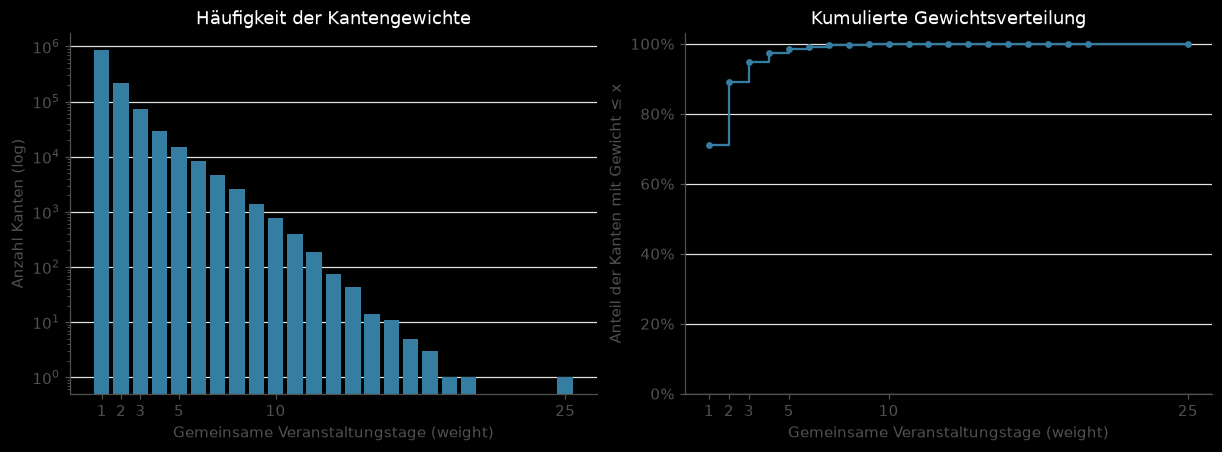

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')

axes[0].bar(weight_frequency.index, weight_frequency['Kanten'],
            color=COLOR, width=0.8)
axes[0].set_yscale('log')
axes[0].set(xlabel='Gemeinsame Veranstaltungstage (weight)', ylabel='Anzahl Kanten (log)',
            title='Häufigkeit der Kantengewichte')

cumulative_share = weight_frequency['Anteil'].cumsum()
axes[1].step(cumulative_share.index, cumulative_share, where='post', color=COLOR)
axes[1].scatter(cumulative_share.index, cumulative_share, color=COLOR, s=12)
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=1))
axes[1].set(xlabel='Gemeinsame Veranstaltungstage (weight)',
            ylabel='Anteil der Kanten mit Gewicht ≤ x', ylim=(0, 1.03),
            title='Kumulierte Gewichtsverteilung')

for ax in axes:
    ax.set_xticks(sorted(set(THRESHOLDS + [int(weights.max())])))
    ax.grid(axis='x', visible=False)
plt.show()

Die Häufigkeiten fallen mit steigenden Gewichten stark ab. Die logarithmische Achse macht auch seltene hohe Gewichte sichtbar. Median und oberes Quartil zeigen, ob sich ein Grossteil der Kanten auf wenige gemeinsame Tage beschränkt. Ein höheres Mindestgewicht behält wiederholt beobachtete gemeinsame Tage bei; es belegt keine persönliche Bekanntschaft.

## 4.3 Weight-Thresholds vergleichen

Eine Kante bleibt genau dann erhalten, wenn `weight >= min_weight`. Alle Athleten bleiben im Graphen, auch wenn sie nach dem Filtern isoliert sind. Die GC-Anteile haben dadurch für alle Thresholds denselben Nenner.

Kantenfilter werden als `subgraph_view` erstellt: Sie teilen die Daten mit `G` und benötigen keine Kopie der Kantenattribute. Für Threshold 1 verwenden wir die bereits berechneten Komponenten des vollständigen Graphen. Die Kantenanzahl ergibt sich direkt aus dem einmal eingelesenen Gewichtsarray.

In [10]:
rows = []
for threshold in THRESHOLDS:
    if threshold == 1:
        H = G
        summary = full_summary.copy()
    else:
        H = nx.subgraph_view(
            G,
            filter_edge=lambda u, v, minimum=threshold: G[u][v]['weight'] >= minimum,
        )
        summary, _ = component_summary(H)

    rows.append({
        'min_weight': threshold,
        'nodes': H.number_of_nodes(),
        'edges': int(weights.ge(threshold).sum()),
        **summary,
    })
    del H

comparison = pd.DataFrame(rows).set_index('min_weight')
comparison['edge_share'] = comparison['edges'] / n_edges
comparison = comparison[[
    'nodes', 'edges', 'edge_share', 'isolates', 'components',
    'giant_component_nodes', 'giant_component_share',
]]

# Kontrollieren, dass ausschliesslich Kanten reduziert wurden.
assert comparison['nodes'].eq(n_nodes).all()
assert comparison.loc[1, 'edges'] == n_edges
assert comparison['edges'].is_monotonic_decreasing
assert comparison['isolates'].is_monotonic_increasing
assert comparison['components'].is_monotonic_increasing
assert comparison['giant_component_nodes'].is_monotonic_decreasing
assert comparison['giant_component_nodes'].le(n_nodes).all()
assert G.number_of_nodes() == n_nodes and G.number_of_edges() == n_edges

comparison_display = comparison.copy()
for column in ['edge_share', 'giant_component_share']:
    comparison_display[column] = comparison_display[column].map('{:.2%}'.format)
comparison_display = comparison_display.rename(columns={
    'nodes': 'Knoten', 'edges': 'Kanten', 'edge_share': 'Kantenanteil am Vollgraphen',
    'isolates': 'Isolierte Knoten', 'components': 'Connected Components',
    'giant_component_nodes': 'GC-Knoten', 'giant_component_share': 'GC-Anteil an allen Knoten',
})
comparison_display.index = [f'≥ {value}' for value in comparison_display.index]
comparison_display.index.name = 'Mindestgewicht'
display(comparison_display)

,Knoten,Kanten,Kantenanteil am Vollgraphen,Isolierte Knoten,Connected Components,GC-Knoten,GC-Anteil an allen Knoten
Mindestgewicht,,,,,,,
≥ 1,13156,1231245,100.00%,20,23,13132,99.82%
≥ 2,13156,357219,29.01%,413,428,12709,96.60%
≥ 3,13156,135353,10.99%,1771,1835,11209,85.20%
≥ 5,13156,33442,2.72%,6188,6432,5416,41.17%
≥ 10,13156,1503,0.12%,11915,12168,95,0.72%


## 4.4 Einfluss auf Kantenzahl und Zusammenhalt

Die linke Abbildung zeigt die verbleibenden Kanten, die rechte den Anteil aller Athleten in der Giant Component. Die x-Achse verwendet die tatsächlichen Mindestgewichte. Die Prozentangaben links beziehen sich auf die ursprüngliche Kantenanzahl.

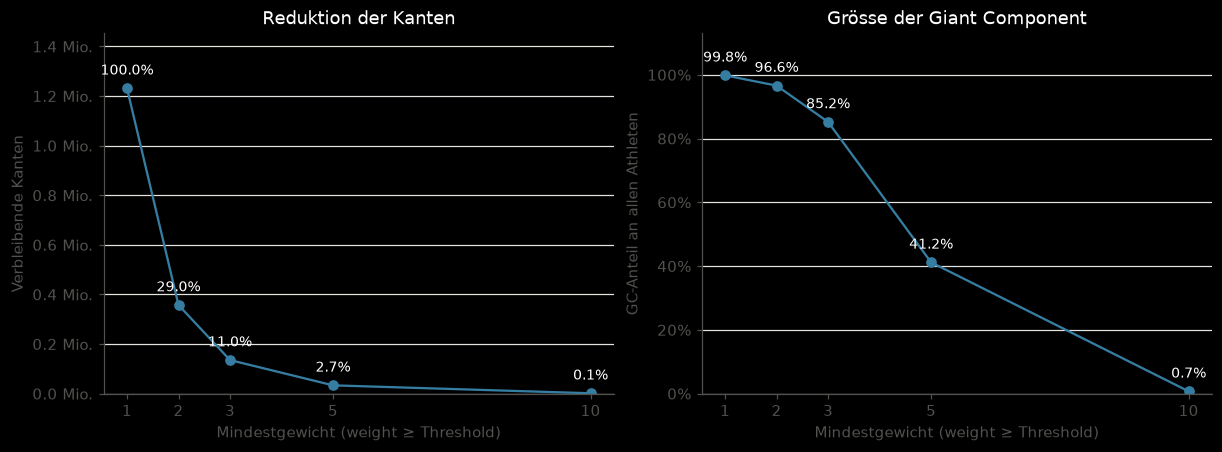

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')

axes[0].plot(comparison.index, comparison['edges'], marker='o', color=COLOR)
axes[0].yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f'{value / 1_000_000:.1f} Mio.')
)
axes[0].set(xlabel='Mindestgewicht (weight ≥ Threshold)', ylabel='Verbleibende Kanten',
            ylim=(0, n_edges * 1.18), title='Reduktion der Kanten')
for threshold, row in comparison.iterrows():
    axes[0].annotate(f"{row['edge_share']:.1%}",
                     (threshold, row['edges']), xytext=(0, 9),
                     textcoords='offset points', ha='center', fontsize=9)

axes[1].plot(comparison.index, comparison['giant_component_share'],
             marker='o', color=COLOR)
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=1))
axes[1].set(xlabel='Mindestgewicht (weight ≥ Threshold)',
            ylabel='GC-Anteil an allen Athleten', ylim=(0, 1.13),
            title='Grösse der Giant Component')
for threshold, row in comparison.iterrows():
    axes[1].annotate(f"{row['giant_component_share']:.1%}",
                     (threshold, row['giant_component_share']), xytext=(0, 9),
                     textcoords='offset points', ha='center', fontsize=9)

for ax in axes:
    ax.set_xticks(THRESHOLDS)
    ax.grid(axis='x', visible=False)
plt.show()

## 4.5 Einordnung und Wahl des Thresholds

Das vollständige Netzwerk umfasst **13'156 Athleten und 1'231'245 Kanten**. Seine Giant Component enthält **13'132 Athleten (99.82 %)**; daneben bestehen 20 isolierte Knoten und zwei weitere kleine Komponenten. Die Giant Component wird hier als Referenz ausgewiesen, während der vollständige Graph die Ausgangsbasis bleibt.

Die Gewichte konzentrieren sich auf wenige Tage: **Median 1**, 75%-Quantil 2, 90%-Quantil 3, 95%-Quantil 4 und 99%-Quantil 6; das Maximum beträgt 25. Kanten mit Gewicht 1 machen **71.0 %** aller Verbindungen aus.

Für spätere Analysen erscheint **`weight >= 2` als sinnvoller Ausgangspunkt**: Die Zahl der Kanten sinkt auf **357'219 (−71.0 %)**, während **96.6 % aller Athleten** in der Giant Component bleiben. Gleichzeitig steigt die Zahl isolierter Knoten von 20 auf 413. Damit werden Verbindungen aus nur einem gemeinsamen Veranstaltungstag entfernt, bei weiterhin hoher Abdeckung.

**`weight >= 3`** reduziert stärker auf **135'353 Kanten (−89.0 %)**. Die Giant Component umfasst noch **85.2 %**, und 1'771 Athleten sind isoliert. Dieser Threshold ist eine sinnvolle strengere Vergleichsvariante und entspricht dem in der Modellierung beschriebenen Gephi-Filter. **`weight >= 5` und `>= 10`** fragmentieren das Netzwerk stark: Der GC-Anteil fällt auf **41.2 % beziehungsweise 0.72 %**. Für Analysen mit breiter Athletenabdeckung erscheinen diese Thresholds deshalb weniger geeignet.

Die Reduktion bevorzugt Athletenpaare mit wiederholt gespeicherten gemeinsamen Veranstaltungstagen. Da nur Bestleistungen aus TOP100-Listen vorliegen, können selten beobachtete Verbindungen und Athleten mit geringer Datenabdeckung besonders häufig entfallen. Gemeinsame Tage sind weder vollständige Teilnahmehistorien noch ein Nachweis sozialer Beziehungen. Die Wahl von Threshold 2 ist daher ein begründeter Kompromiss aus Reduktion und Abdeckung; spätere Aussagen sollten ihre Abhängigkeit vom Threshold berücksichtigen.